Saving Iris.csv to Iris (2).csv
DATASET OVERVIEW

First 5 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset shape: (150, 6)

Column data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float

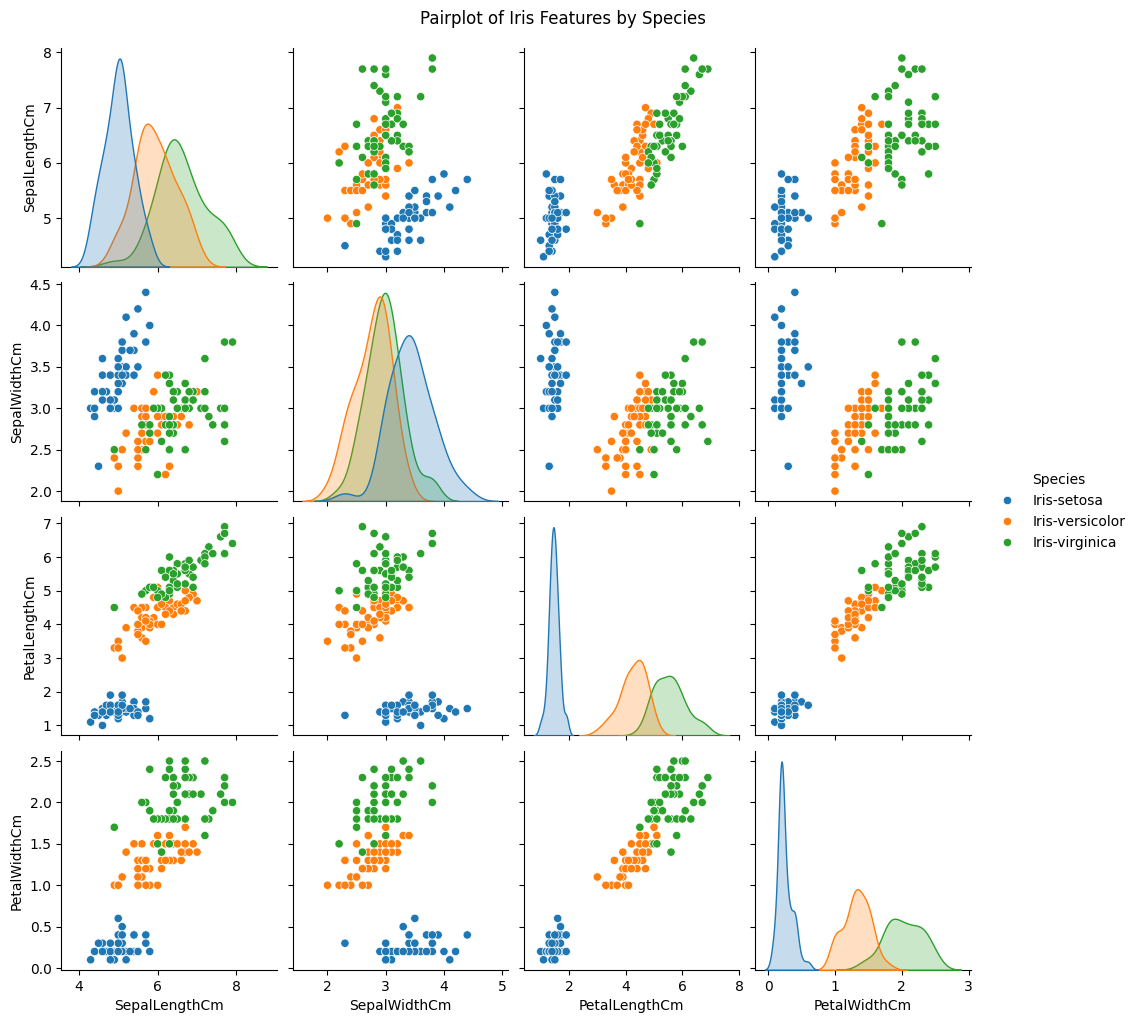

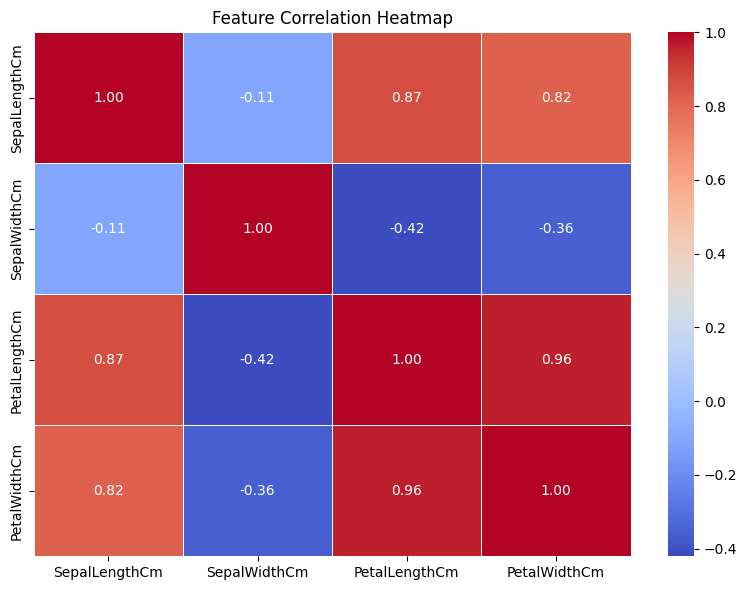

/tmp/ipykernel_1050/854131968.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Species", y=col, data=df, palette="Set2")
/tmp/ipykernel_1050/854131968.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Species", y=col, data=df, palette="Set2")
/tmp/ipykernel_1050/854131968.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Species", y=col, data=df, palette="Set2")
/tmp/ipykernel_1050/854131968.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` va

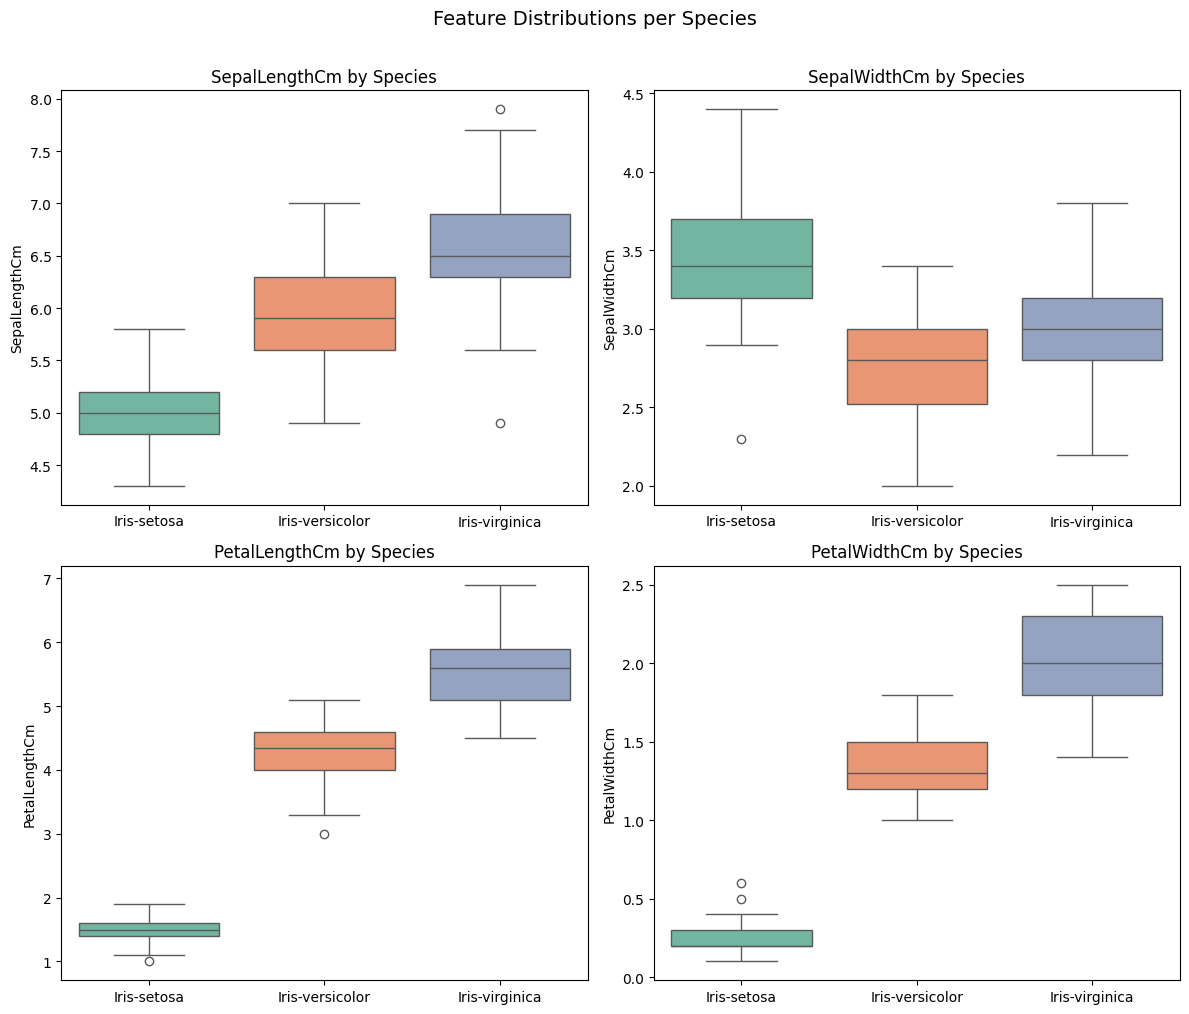


LABEL ENCODING

Species → Integer mapping:
  Iris-setosa → 0
  Iris-versicolor → 1
  Iris-virginica → 2

TRAIN-TEST SPLIT

Training samples : 117
Test samples     : 30

K TUNING — FINDING BEST K FOR KNN

Best k found     : 6
Best CV accuracy : 0.9729


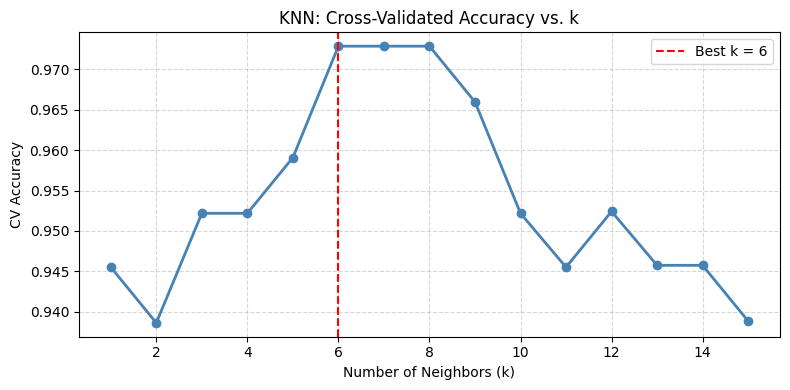


MODEL TRAINING

All models trained successfully.

KNN EVALUATION (k=6)

Test Accuracy: 0.9333


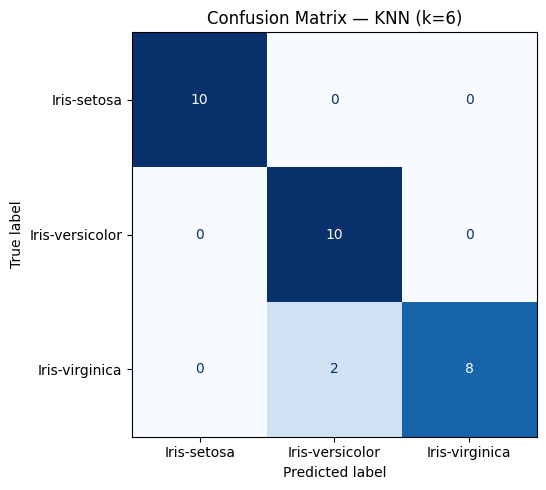


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30


MODEL COMPARISON

               Model  Test Accuracy
          KNN (k=6)       0.933333
Logistic Regression       0.933333
      Decision Tree       0.933333


/tmp/ipykernel_1050/854131968.py:310: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


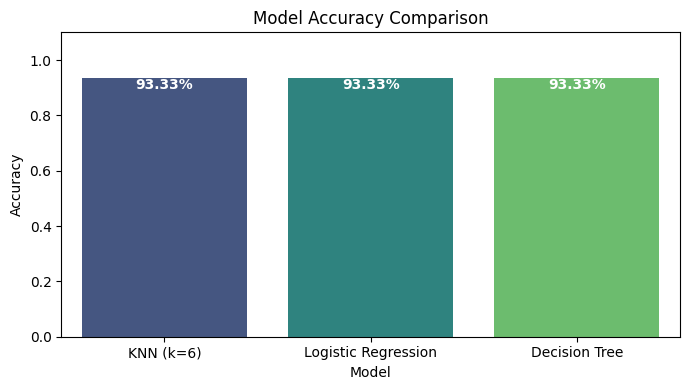


CROSS-VALIDATION — KNN WITH PIPELINE

Fold accuracies  : ['0.9667', '0.9667', '1.0000', '0.9310', '1.0000']
Mean CV Accuracy : 0.9729
Std Dev          : 0.0257

PREDICT YOUR OWN FLOWER

Enter the flower measurements below (in centimeters):

  Sepal Length (cm): 3
  Sepal Width  (cm): 4
  Petal Length (cm): 6
  Petal Width  (cm): 8


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



----------------------------------------
  🌸 Predicted Species : Iris-virginica

  Confidence per species:
    Iris-setosa            0.0%  
    Iris-versicolor        0.0%  
    Iris-virginica         100.0%  ████████████████████
----------------------------------------

Do you know the real species? (yes / no): no


In [3]:
# ---------------- IMPORTS ----------------
# Standard library
import numpy as np
import pandas as pd
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Scikit-learn — preprocessing & utilities
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
# Scikit-learn — models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
# Scikit-learn — evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# ============================================================
# SECTION 1 — DATA LOADING
# Upload the CSV file
from google.colab import files
files.upload()
df = pd.read_csv("Iris.csv")

# ============================================================
# SECTION 2 — DATA EXPLORATION
print("DATASET OVERVIEW")
print("\nFirst 5 rows:")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nDataset Informations:")
df.info()
print("\nStatistical summary:")
print(df.describe())

# ============================================================
# SECTION 3 — DATA CLEANING
# The 'Id' column is a row identifier with no predictive value(not useful)
df = df.drop("Id", axis=1)
print("DATA CLEANING")
# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())
# Check and remove exact duplicate rows to avoid biasing the model
n_duplicates = df.duplicated().sum()
print(f"\nDuplicate rows found: {n_duplicates}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nDataset shape after cleaning: {df.shape}")
print("\nStatistical summary after cleaning:")
print(df.describe())

# ============================================================
# SECTION 4 — EXPLORATORY DATA ANALYSIS (EDA)
print("EXPLORATORY DATA ANALYSIS")
print("\nClass distribution (samples per species):")
print(df["Species"].value_counts())
print("\nMean feature values per species:")
print(df.groupby("Species").mean(numeric_only=True))
# --- Pairplot ---
# Shows relationships between all features
# Helps identify which features best separate the classes.
sns.pairplot(df, hue="Species", diag_kind="kde")
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()
# --- Correlation Heatmap ---
# Reveals linear correlations between numeric features.
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()
# --- Boxplots ---
# Shows the distribution and spread of each feature per species.
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
plt.figure(figsize=(12, 10))
for i, col in enumerate(feature_cols):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x="Species", y=col, data=df, palette="Set2")
    plt.title(f"{col} by Species")
    plt.xlabel("")
plt.suptitle("Feature Distributions per Species", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# ============================================================
# SECTION 5 — ENCODING
# Convert the string species labels to integers so sklearn can process them.
# LabelEncoder assigns: Iris-setosa=0, Iris-versicolor=1, Iris-virginica=2
le = LabelEncoder()
df["Species_encoded"] = le.fit_transform(df["Species"])
print("\n" + "=" * 55)
print("LABEL ENCODING")
print("=" * 55)
print("\nSpecies → Integer mapping:")
for idx, species in enumerate(le.classes_):
    print(f"  {species} → {idx}")

# ============================================================
# SECTION 6 — FEATURE AND TARGET SELECTION
X = df[feature_cols]   # Input features (measurements)
y = df["Species_encoded"]  # Target labels (encoded species)

# ============================================================
# SECTION 7 — TRAIN-TEST SPLIT
# stratify=y ensures each species is represented proportionally
# in both train and test sets, preventing imbalanced splits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("TRAIN-TEST SPLIT")
print(f"\nTraining samples : {len(X_train)}")
print(f"Test samples     : {len(X_test)}")

# ============================================================
# SECTION 8 — FEATURE SCALING
# KNN relies on distance between points, so features must be on
# the same scale. StandardScaler transforms each feature to have
# mean=0 and std=1. We fit ONLY on training data to prevent
# information from the test set leaking into the model.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================
# SECTION 9 — K TUNING (Finding the Best K for KNN)
# Instead of guessing k=3, we evaluate k values from 1 to 15
# using 5-fold cross-validation on a Pipeline. Using a Pipeline
# ensures the scaler is fitted only on training folds ,
# which prevents data leakage
print("K TUNING — FINDING BEST K FOR KNN")
k_range = range(1, 16)
cv_scores = []

for k in k_range:

    knn_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(knn_pipeline, X, y, cv=5, scoring="accuracy")
    cv_scores.append(scores.mean())

best_k = k_range[np.argmax(cv_scores)]
print(f"\nBest k found     : {best_k}")
print(f"Best CV accuracy : {max(cv_scores):.4f}")

# Visualize how accuracy changes with k
plt.figure(figsize=(8, 4))
plt.plot(k_range, cv_scores, marker="o", color="steelblue", linewidth=2)
plt.axvline(x=best_k, color="red", linestyle="--", label=f"Best k = {best_k}")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("CV Accuracy")
plt.title("KNN: Cross-Validated Accuracy vs. k")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ============================================================
# SECTION 10 — MODEL TRAINING
print("MODEL TRAINING")
# --- Primary Model: KNN with best k ---
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_scaled, y_train)
# --- Comparison Model: Logistic Regression ---
lr_model = LogisticRegression(max_iter=200, random_state=42)
lr_model.fit(X_train_scaled, y_train)
# --- Comparison Model: Decision Tree ---
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
print("\nAll models trained successfully.")

# ============================================================
# SECTION 11 — EVALUATION (KNN — Primary Model)
print(f"KNN EVALUATION (k={best_k})")
y_pred = knn_model.predict(X_test_scaled)

# Accuracy: overall fraction of correct predictions
knn_accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {knn_accuracy:.4f}")

# Confusion Matrix: rows = actual class, columns = predicted class.
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title(f"Confusion Matrix — KNN (k={best_k})")
plt.tight_layout()
plt.show()

# Classification Report: precision, recall, and F1-score per class.
# - Precision: of all predicted as class X, how many truly are X?
# - Recall   : of all actual class X samples, how many did we catch?
# - F1-score : harmonic mean of precision and recall (balance between both)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# ============================================================
# SECTION 12 — MODEL COMPARISON
print("MODEL COMPARISON")
acc_lr = accuracy_score(y_test, lr_model.predict(X_test_scaled))
acc_dt = accuracy_score(y_test, dt_model.predict(X_test_scaled))

comparison_df = pd.DataFrame({
    "Model": [f"KNN (k={best_k})", "Logistic Regression", "Decision Tree"],
    "Test Accuracy": [knn_accuracy, acc_lr, acc_dt],
})

print("\n", comparison_df.to_string(index=False))
plt.figure(figsize=(7, 4))
bars = sns.barplot(
    x="Model",
    y="Test Accuracy",
    data=comparison_df,
    palette="viridis",
)
# Annotate bars with accuracy values
for bar, acc in zip(bars.patches, comparison_df["Test Accuracy"]):
    bars.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 0.05,
        f"{acc:.2%}",
        ha="center",
        va="bottom",
        color="white",
        fontweight="bold",
    )
plt.title("Model Accuracy Comparison")
plt.ylim(0, 1.1)
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

# ============================================================
# SECTION 13 — CROSS-VALIDATION (KNN with Pipeline)
print("CROSS-VALIDATION — KNN WITH PIPELINE")

final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])

cv_results = cross_val_score(final_pipeline, X, y, cv=5, scoring="accuracy")

print(f"\nFold accuracies  : {[f'{s:.4f}' for s in cv_results]}")
print(f"Mean CV Accuracy : {cv_results.mean():.4f}")
print(f"Std Dev          : {cv_results.std():.4f}")

# ============================================================
# SECTION 14 — USER PREDICTION
print("PREDICT YOUR OWN FLOWER")
print("\nEnter the flower measurements below (in centimeters):\n")
sepal_length = float(input("  Sepal Length (cm): "))
sepal_width  = float(input("  Sepal Width  (cm): "))
petal_length = float(input("  Petal Length (cm): "))
petal_width  = float(input("  Petal Width  (cm): "))

user_data = np.array([[sepal_length, sepal_width, petal_length, petal_width]])

# Scale the user's input using the same scaler fitted on training data
user_data_scaled = scaler.transform(user_data)

# Predicted class
user_pred_encoded = knn_model.predict(user_data_scaled)
user_pred_class   = le.inverse_transform(user_pred_encoded)[0]

# Prediction probabilities for each species
user_proba = knn_model.predict_proba(user_data_scaled)[0]

print(f"  🌸 Predicted Species : {user_pred_class}")
print("\n  Confidence per species:")
for species, prob in zip(le.classes_, user_proba):
    bar = "█" * int(prob * 20)
    print(f"    {species:<22} {prob:.1%}  {bar}")

check = input("\nDo you know the real species? (yes / no): ").strip().lower()

if check == "yes":
    print("\nOptions: Iris-setosa  |  Iris-versicolor  |  Iris-virginica")
    true_label = input("Enter real species: ").strip()

    if true_label == user_pred_class:
        print("\n  ✅ Correct prediction!")
    else:
        print(f"\n  ❌ Wrong prediction. Model predicted '{user_pred_class}', actual was '{true_label}'.")